In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib, time
ROOT = "/content/drive/MyDrive/simuteh-2330511091"
SRC = f"{ROOT}/src"
if SRC not in sys.path:
    sys.path.insert(0, SRC)
importlib.invalidate_caches()
os.chdir(f"{ROOT}/notebook")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
print("OK", os.getcwd())

Mounted at /content/drive
OK /content/drive/MyDrive/simuteh-2330511091/notebook


In [ ]:
def konvolusi(img, k):                      # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):               # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

kernel = {"rerata": np.ones((3, 3)) / 9,
          "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}
for nm, k in kernel.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.266 s, filter2D=0.01855 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.481 s, filter2D=0.00036 s


In [ ]:
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):                  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):        # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih,
20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.72
1   gauss_10  rerata_3    36.85      0.12  6.04
2   gauss_10  rerata_5    37.48      0.14  6.00
3   gauss_10   gauss_5    37.66      0.26  6.17
4   gauss_10  median_3    35.50      0.09  6.08
5   gauss_10  median_5    38.46      0.73  6.81
6   gauss_10  median_9    38.78     14.40  7.00
7   gauss_20     tanpa    22.12      0.00  2.08
8   gauss_20  rerata_3    31.42      0.12  4.67
9   gauss_20  rerata_5    34.39      0.14  5.34
10  gauss_20   gauss_5    32.55      0.26  4.98
11  gauss_20  median_3    29.73      0.09  4.23
12  gauss_20  median_5    33.46      0.73  5.37
13  gauss_20  median_9    35.66     14.11  5.77
14  gauss_40     tanpa    16.55      0.00  1.06
15  gauss_40  rerata_3    25.96      0.11  2.91
16  gauss_40  rerata_5    29.79      0.14  4.00
17  gauss_40   gauss_5    27.16      0.26  3.25
18  gauss_40  median_3    23.83      0.09  2.43
19  gauss_40  median_5    27.84      0.7

          PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
tanpa       22.12  19.06     0.00   0.00     2.08  1.53
rerata_3    31.42  28.22     0.12   0.11     4.67  3.90
rerata_5    34.39  31.41     0.14   0.14     5.34  4.87
gauss_5     32.55  29.30     0.26   0.26     4.98  4.25
median_3    29.73  47.90     0.09   0.11     4.23  7.17
median_5    33.46  45.11     0.73   0.73     5.37  7.05
median_9    35.66  40.83    14.11  13.99     5.77  7.14


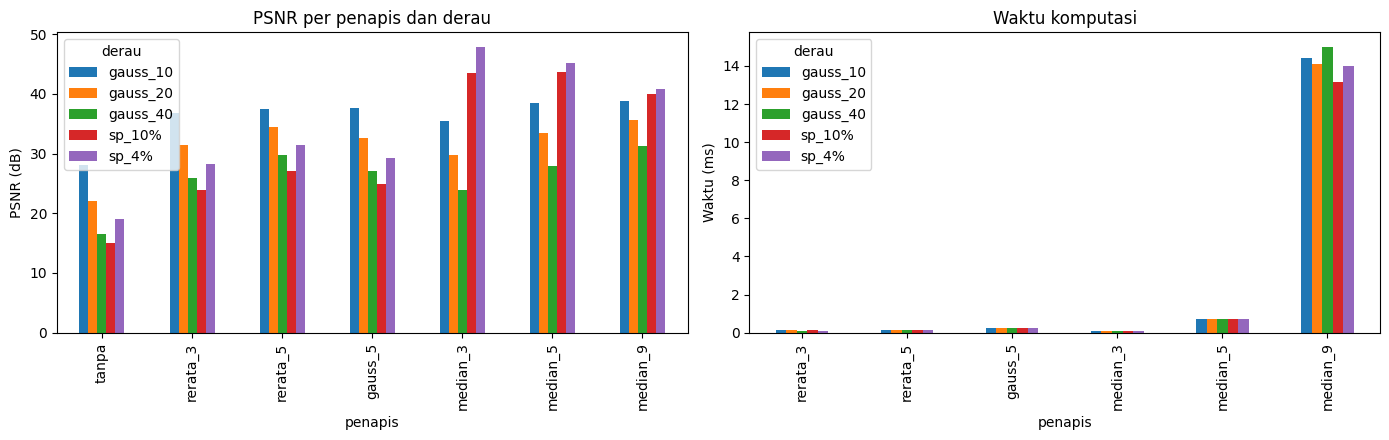

In [ ]:
urut = ["tanpa", "rerata_3", "rerata_5", "gauss_5", "median_3", "median_5", "median_9"]
sub = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])]
t11 = sub.pivot(index="penapis", columns="derau", values=["PSNR_dB", "waktu_ms", "KB"]).reindex(urut)
print(t11)
t11.to_csv("../hasil/b4_tabel11.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").reindex(urut).plot.bar(ax=ax[0])
ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR per penapis dan derau")
tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau", values="waktu_ms").reindex(urut[1:]).plot.bar(ax=ax[1])
ax[1].set_ylabel("Waktu (ms)"); ax[1].set_title("Waktu komputasi")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr_waktu.png", dpi=150); plt.show()


           dI    KB
kernel             
1       29.34  4.61
3       29.78  4.75
5       28.55  4.63
9       22.12  4.09
15       7.43  1.91


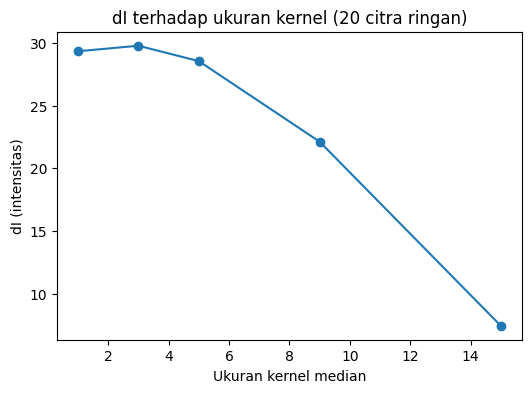

In [ ]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:              # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rata)
rata.to_csv("../hasil/b4_median_bercak.csv")

plt.figure(figsize=(6, 4))
plt.plot(rata.index, rata["dI"], "o-")
plt.xlabel("Ukuran kernel median"); plt.ylabel("dI (intensitas)")
plt.title("dI terhadap ukuran kernel (20 citra ringan)")
plt.savefig("../hasil/b4_di_kernel.png", dpi=150); plt.show()

In [ ]:
 def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0                         # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))           # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))           # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.40 sigma_latar=8.0 | redam->tajam PSNR=30.20 sigma_latar=8.3
Median: tajam->redam PSNR=30.17 sigma_latar=8.2 | redam->tajam PSNR=31.11 sigma_latar=7.3
